In [16]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import random
import warnings
warnings.filterwarnings('ignore')

In [17]:
data = np.load('mnist.npz')
print(data.files)
x_train, x_test, y_train, y_test = data['x_train'], data['x_test'], data['y_train'], data['y_test']

['x_test', 'x_train', 'y_train', 'y_test']


In [18]:
m, n= np.max(x_train), np.min(x_train)
x_train, x_test = (x_train-n)/(m-n), (x_test-n)/(m-n)

In [19]:
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

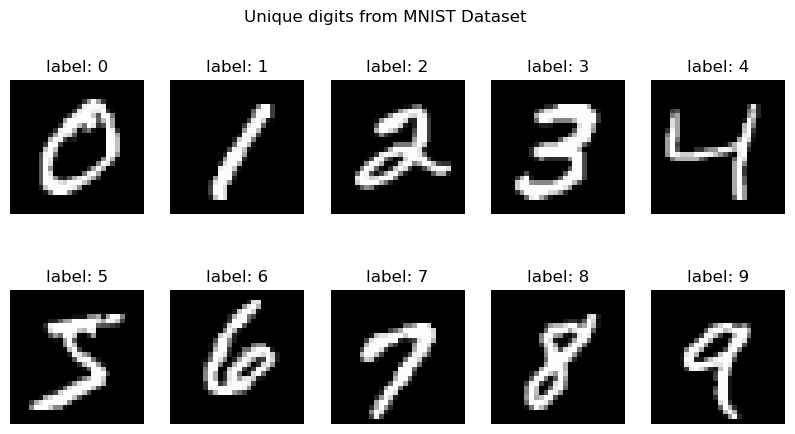

In [21]:
unique_labels, idx = np.unique(y_train, return_index = True)
fig, ax = plt.subplots(2,5, figsize=(10,5))
for i, label in enumerate(unique_labels):
    ax.flat[i].imshow(x_train[idx[i]], cmap='gray')
    ax.flat[i].set_title(f"label: {label}")
    ax.flat[i].axis("off")
plt.suptitle("Unique digits from MNIST Dataset")
plt.show()

In [24]:
model = keras.Sequential([
    #Convolutional Block1: Detects basic edges and lines
    layers.Conv2D(32, kernel_size=(3,3), activation = 'relu', input_shape= (28,28,1)),
    layers.MaxPooling2D(pool_size=(2,2)),

    #Convolutional Block2: Detects complex shapes & loops
    layers.Conv2D(64, kernel_size=(3,3), activation = 'relu'),
    layers.MaxPooling2D(pool_size=(2,2)),

    #Classification head (fully connected / fnn part)
    layers.Flatten(),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])    

In [25]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [27]:
history = model.fit(x_train, y_train, epochs=10, validation_split=0.2, verbose=1)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9530 - loss: 0.1552 - val_accuracy: 0.9843 - val_loss: 0.0524
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9834 - loss: 0.0510 - val_accuracy: 0.9862 - val_loss: 0.0452
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9887 - loss: 0.0367 - val_accuracy: 0.9898 - val_loss: 0.0352
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9910 - loss: 0.0275 - val_accuracy: 0.9913 - val_loss: 0.0324
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9921 - loss: 0.0238 - val_accuracy: 0.9918 - val_loss: 0.0305
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9941 - loss: 0.0180 - val_accuracy: 0.9904 - val_loss: 0.0358
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9954 - loss: 0.0142 - val_accuracy: 0.9907 - val_loss: 0.0355
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9954 - loss: 0.0

In [28]:
loss, acc = model.evaluate(x_test, y_test, verbose=1)
print(f"test accuracy: {acc*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9910 - loss: 0.0394    
test accuracy: 99.10%


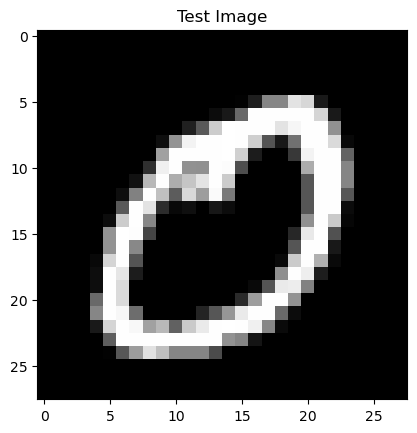

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
predicted:  0


In [29]:
n = random.randint(0,len(x_test)-1)
plt.imshow(x_test[n], cmap='gray')
plt.title("Test Image")
plt.show()
pred= np.argmax(model.predict(np.expand_dims(x_test[n], axis=0))[0])
print("predicted: ", pred)

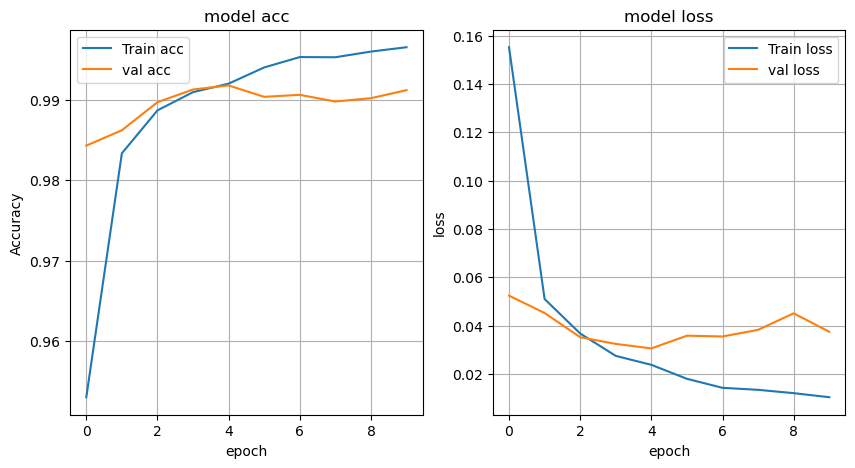

In [32]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label="Train acc")
plt.plot(history.history['val_accuracy'], label="val acc")
plt.title("model acc")
plt.xlabel("epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label="Train loss")
plt.plot(history.history['val_loss'], label="val loss")
plt.title("model loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.grid()
plt.show()